In [1]:
# Install the packages this notebook needs.
# If they are already installed, this step is quick and harmless.
%pip install -q pandas numpy matplotlib seaborn scipy

Note: you may need to restart the kernel to use updated packages.


# 05. Biggest movers: the freedom momentum score

## Words first: the original metric of this project

The freedom momentum score is a simple idea built for this
project. For each country, take its overall freedom score in
2016 and subtract its score in 2008. That difference is the
momentum over eight years. Divide by eight to get the average
change per year.

A change of plus 0.25 points or more is labelled rising. A change
of minus 0.25 points or less is labelled falling. Anything in
between is labelled steady. The 0.25 cut is a reading aid chosen
for this project, not a threshold used by Cato or the Fraser
Institute. A country just above or just below the cut is not
meaningfully different from one just on the other side. The
labels help sort the table, they do not draw a hard line in
real life.

Momentum is reported for the overall score, and also split into
personal freedom change and economic freedom change, so a reader
can see which half drove the move.

In [2]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.figsize'] = (10, 6)
ROOT = pathlib.Path('..').resolve()
CHARTS = ROOT / 'charts'
CHARTS.mkdir(exist_ok=True)
DATA = ROOT / 'data' / 'processed'
print('Data folder:', DATA)
print('Charts folder:', CHARTS)

Data folder: /home/hatch/workspace/repo-builds/human-freedom-index/data/processed
Charts folder: /home/hatch/workspace/repo-builds/human-freedom-index/charts


In [3]:
momentum = pd.read_csv(DATA / 'freedom_momentum.csv')
print('Countries with scores in both 2008 and 2016:', len(momentum))
print(momentum['momentum_label'].value_counts().to_string())
print()
print('Largest rises, 2008 to 2016:')
print(momentum.head(10)[['country', 'region', 'hf_score_2008',
                         'hf_score_2016', 'hf_change_2008_2016',
                         'pf_change_2008_2016',
                         'ef_change_2008_2016']].round(3).to_string(index=False))
print()
print('Largest falls, 2008 to 2016:')
print(momentum.tail(10).iloc[::-1][['country', 'region', 'hf_score_2008',
                                    'hf_score_2016', 'hf_change_2008_2016',
                                    'pf_change_2008_2016',
                                    'ef_change_2008_2016']].round(3).to_string(index=False))

Countries with scores in both 2008 and 2016: 141
momentum_label
steady     89
falling    31
rising     21

Largest rises, 2008 to 2016:
      country             region  hf_score_2008  hf_score_2016  hf_change_2008_2016  pf_change_2008_2016  ef_change_2008_2016
Cote d'Ivoire Sub-Saharan Africa          5.697          6.531                0.835                1.169                 0.50
       Angola Sub-Saharan Africa          4.824          5.641                0.817                0.874                 0.76
     Zimbabwe Sub-Saharan Africa          4.936          5.615                0.680               -0.150                 1.51
       Taiwan          East Asia          7.792          8.466                0.673                0.947                 0.40
      Lesotho Sub-Saharan Africa          5.954          6.534                0.581                0.851                 0.31
     Mongolia          East Asia          7.145          7.699                0.554                0.438    

## The biggest rises

Each bar is the change in overall score from 2008 to 2016. The
table above gives the starting and ending scores, so a large
change from a low start is not confused with a large change from
a high start.

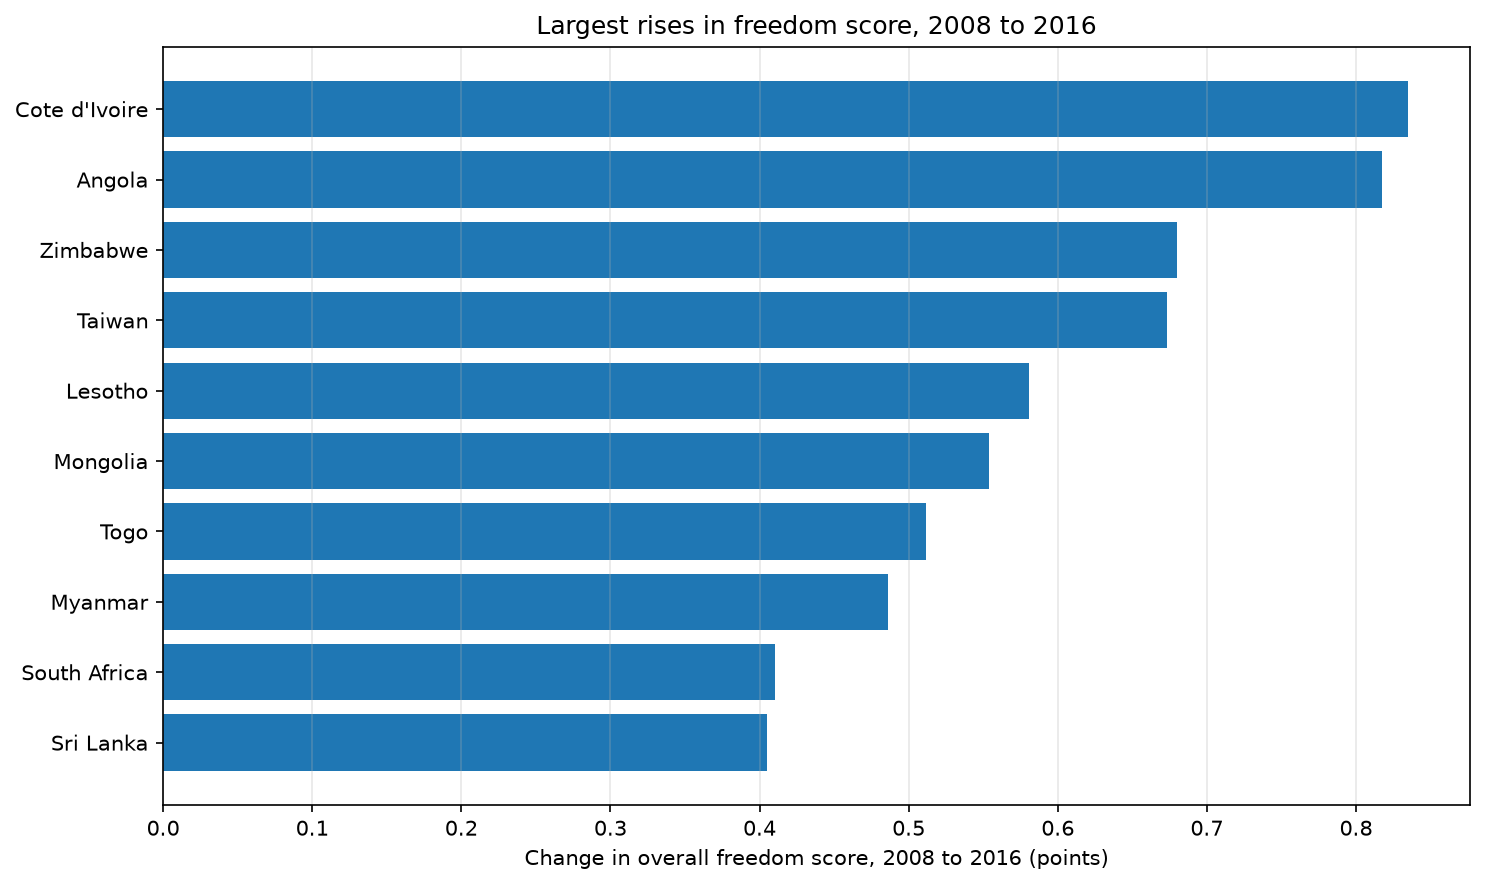

In [4]:
top = momentum.head(10).iloc[::-1]
fig, ax = plt.subplots()
ax.barh(top['country'], top['hf_change_2008_2016'])
ax.set_xlabel('Change in overall freedom score, 2008 to 2016 (points)')
ax.set_title('Largest rises in freedom score, 2008 to 2016')
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS / 'chart_movers_up.png')
plt.show()

## The biggest falls

The same idea, for the other end of the table. Note the scale.
Rises and falls are not symmetric in this period, and the chart
shows that without any extra comment.

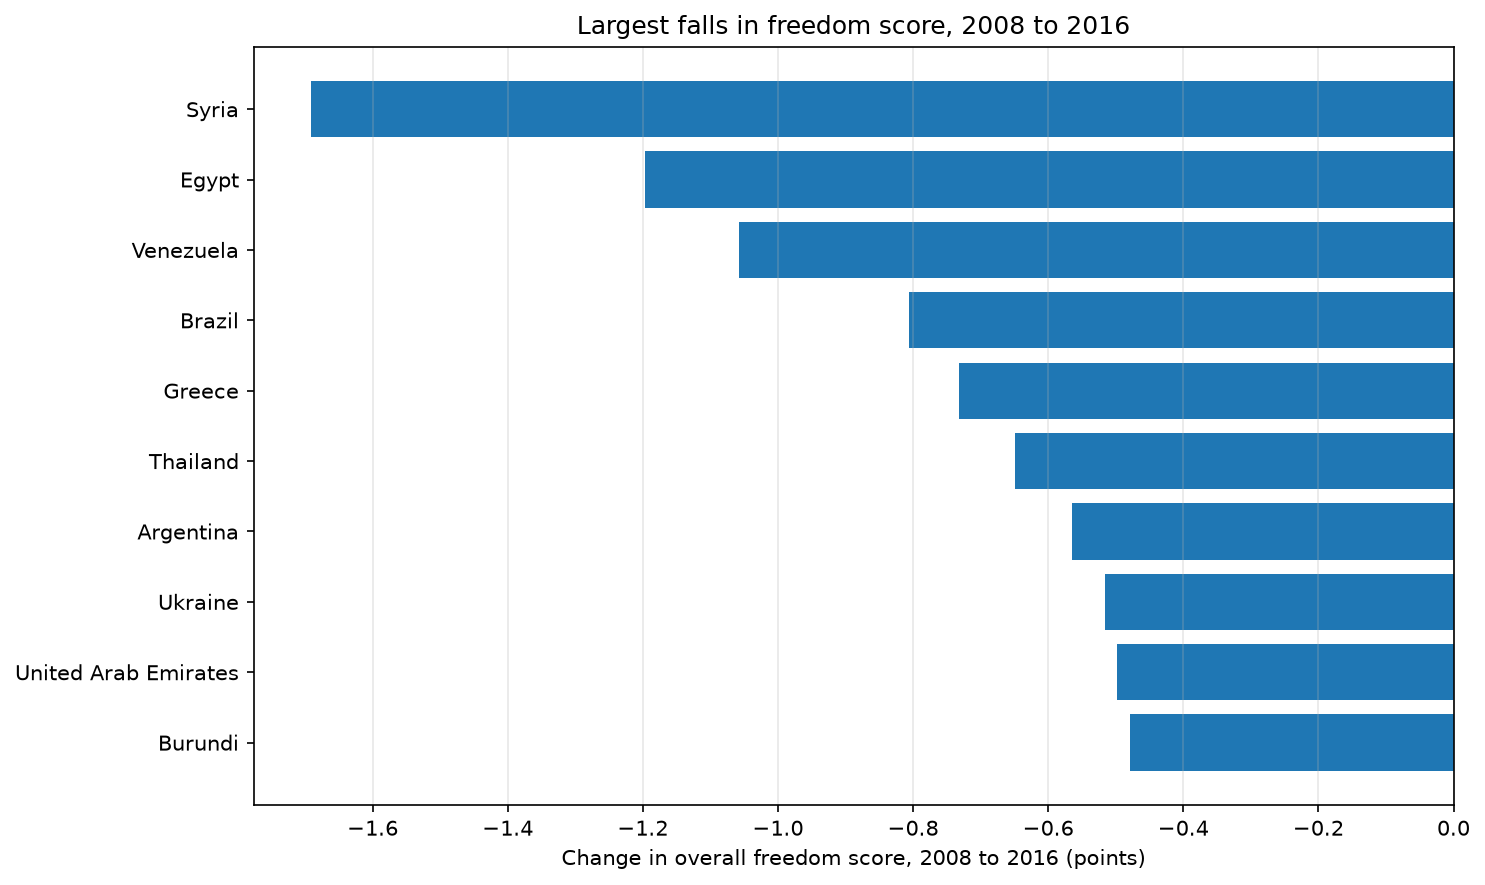

In [5]:
bottom = momentum.tail(10)
fig, ax = plt.subplots()
ax.barh(bottom['country'], bottom['hf_change_2008_2016'])
ax.set_xlabel('Change in overall freedom score, 2008 to 2016 (points)')
ax.set_title('Largest falls in freedom score, 2008 to 2016')
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS / 'chart_movers_down.png')
plt.show()

## How common is each kind of move?

Most countries do not move much in eight years on this index.
The chart below counts rising, steady, and falling countries
using the 0.25 point rule from the start of this notebook.

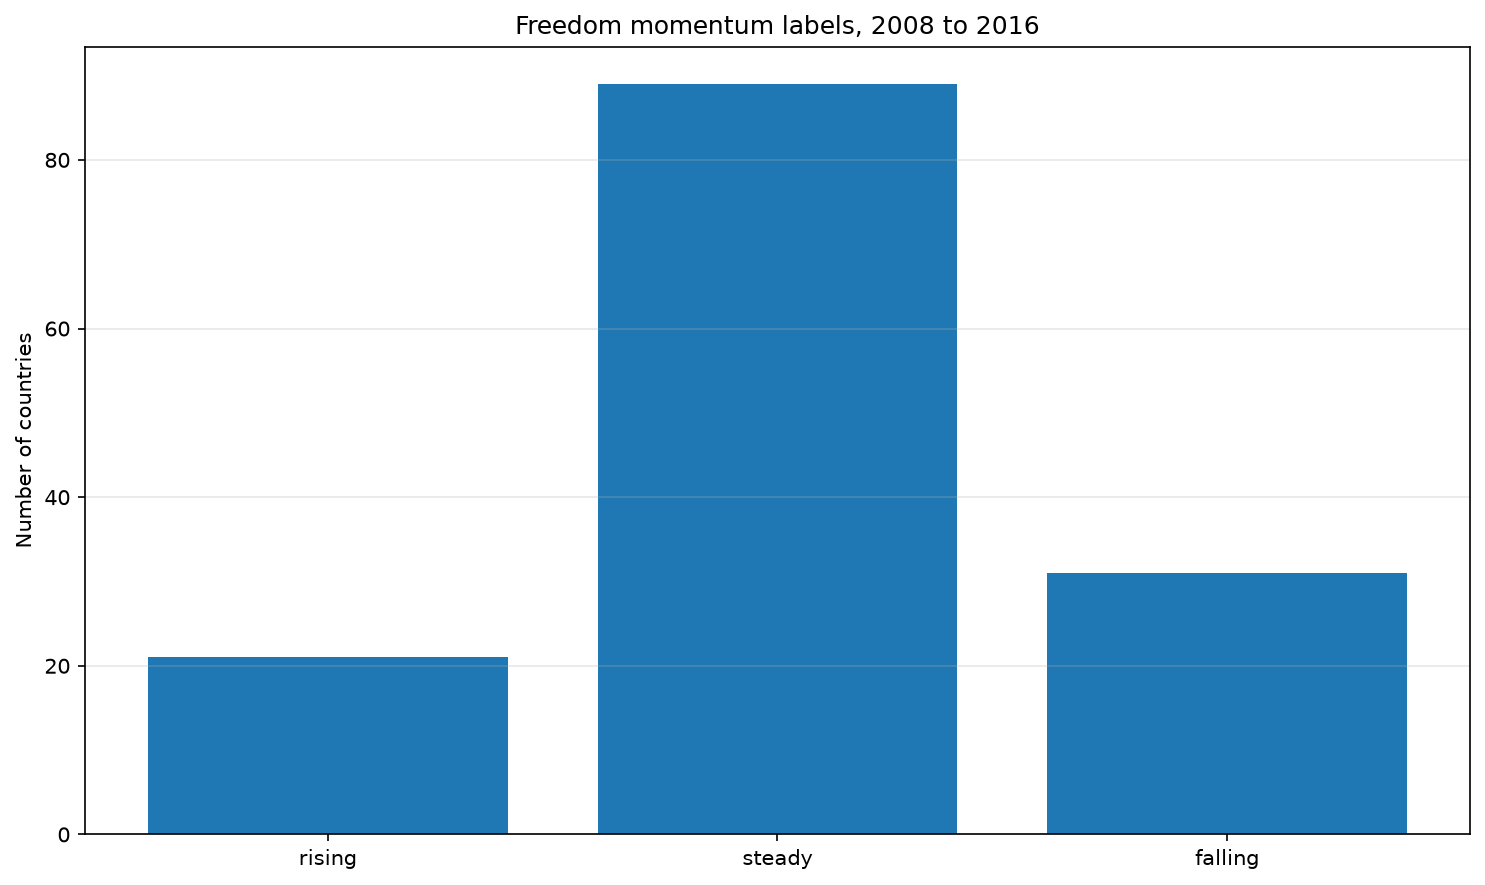

momentum_label
rising     21
steady     89
falling    31


In [6]:
counts = momentum['momentum_label'].value_counts()
order = ['rising', 'steady', 'falling']
counts = counts.reindex(order)
fig, ax = plt.subplots()
ax.bar(counts.index, counts.values)
ax.set_ylabel('Number of countries')
ax.set_title('Freedom momentum labels, 2008 to 2016')
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS / 'chart_momentum_distribution.png')
plt.show()
print(counts.to_string())

## What to take away

Momentum turns a ranking in one year into a story over time.
A country can rank in the middle and still be moving clearly in
one direction, and a country can rank near the top and still be
slipping. The labels are a sorting aid, not a verdict, and the
personal versus economic split shows which half moved.